## Machine Learning CA1

**Programme:** Higher Diploma in Science in Data Analytics for Business - CCT College Dublin

**Module:** Machine Learning    
**Lecturer:** Dr. Muhammad Iqbal      
**Assessment:** Individual CA1  
**Dataset:**  `student-mat.csv` | `student.txt`

**Dataset link:** https://archive.ics.uci.edu/dataset/320/student+performance?utm_source=chatgpt.com

**GitHub link** https://github.com/sba23349-spec/CA1_MachineLearning_sba23349.git

**Deadline** 20/11/2026

## Project Overview:

This dataset contains information about students' academic
performance in Mathematics.

The objective is to predict whether a student will pass
or fail using classification models.


# 1 - Dataset Loading and Initial Inspection

The first step is to load the student dataset and inspect its structure before performing data cleaning and exploratory analysis.

In [1]:
# importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
# Loading the dataset
df_original = pd.read_csv('student-mat.csv', sep=';')

df_original.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


The first five rows were displayed to provide an initial overview of the dataset and verify that the CSV file was imported correctly.

## 1.1 - Dataset Dimensions

The number of rows and columns in the dataset is examined below.

In [5]:
print("Number of rows:", df_original.shape[0])
print("Number of columns:", df_original.shape[1])

Number of rows: 395
Number of columns: 33


The original dataset contains **395 observations and 33 columns**.

## 1.2 - Inspecting Data Types

The structure and data types of the variables were examined to identify whether any variables required conversion before the statistical analysis.

In [6]:
df_original.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

## 1.3 - First Look at Missing Values

Missing values were checked to assess the completeness of the dataset before conducting the statistical analysis.

In [7]:
null_count = df_original.isnull().sum()

print("Number of null values:\n", null_count)

Number of null values:
 school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64


No missing values were identified in this dataset.

## 1.4 - Checking for Duplicate Observations

The dataset was checked for duplicate rows to identify potentially repeated student records.

In [8]:
duplicate_count = df_original.duplicated().sum()

print("Number of duplicated rows:", duplicate_count)

Number of duplicated rows: 0


In [9]:
for column in df_original.columns:
    print(f"\n--- {column} ---")
    print(df_original[column].value_counts(dropna=False))


--- school ---
school
GP    349
MS     46
Name: count, dtype: int64

--- sex ---
sex
F    208
M    187
Name: count, dtype: int64

--- age ---
age
16    104
17     98
18     82
15     82
19     24
20      3
22      1
21      1
Name: count, dtype: int64

--- address ---
address
U    307
R     88
Name: count, dtype: int64

--- famsize ---
famsize
GT3    281
LE3    114
Name: count, dtype: int64

--- Pstatus ---
Pstatus
T    354
A     41
Name: count, dtype: int64

--- Medu ---
Medu
4    131
2    103
3     99
1     59
0      3
Name: count, dtype: int64

--- Fedu ---
Fedu
2    115
3    100
4     96
1     82
0      2
Name: count, dtype: int64

--- Mjob ---
Mjob
other       141
services    103
at_home      59
teacher      58
health       34
Name: count, dtype: int64

--- Fjob ---
Fjob
other       217
services    111
teacher      29
at_home      20
health       18
Name: count, dtype: int64

--- reason ---
reason
course        145
home          109
reputation    105
other          36
Name: count

In [10]:
dictionary_dataset = open("student.txt")
print(dictionary_dataset.read())

# Attributes for both student-mat.csv (Math course) and student-por.csv (Portuguese language course) datasets:
1 school - student's school (binary: "GP" - Gabriel Pereira or "MS" - Mousinho da Silveira)
2 sex - student's sex (binary: "F" - female or "M" - male)
3 age - student's age (numeric: from 15 to 22)
4 address - student's home address type (binary: "U" - urban or "R" - rural)
5 famsize - family size (binary: "LE3" - less or equal to 3 or "GT3" - greater than 3)
6 Pstatus - parent's cohabitation status (binary: "T" - living together or "A" - apart)
7 Medu - mother's education (numeric: 0 - none,  1 - primary education (4th grade), 2 – 5th to 9th grade, 3 – secondary education or 4 – higher education)
8 Fedu - father's education (numeric: 0 - none,  1 - primary education (4th grade), 2 – 5th to 9th grade, 3 – secondary education or 4 – higher education)
9 Mjob - mother's job (nominal: "teacher", "health" care related, civil "services" (e.g. administrative or police), "at_home" or 

In [28]:
df_original['G3'].value_counts().sort_index()

G3
0     38
4      1
5      7
6     15
7      9
8     32
9     28
10    56
11    47
12    31
13    31
14    27
15    33
16    16
17     6
18    12
19     5
20     1
Name: count, dtype: int64

## 2. Exploratory Data Analysis (EDA)

The goal of this section is to explore the dataset and identify possible relationships between students' characteristics and their final Mathematics grades (G3).

The analysis focuses on study time, previous failures, absences and other factors that may be associated with academic performance.

Visualisations and summary statistics will be used to understand the distribution of the data and identify patterns before building the classification models.


### 2.1 Distribution of Final Grades (G3)

This analysis examines the distribution of students' final Mathematics grades to understand how their performance varies across the dataset.


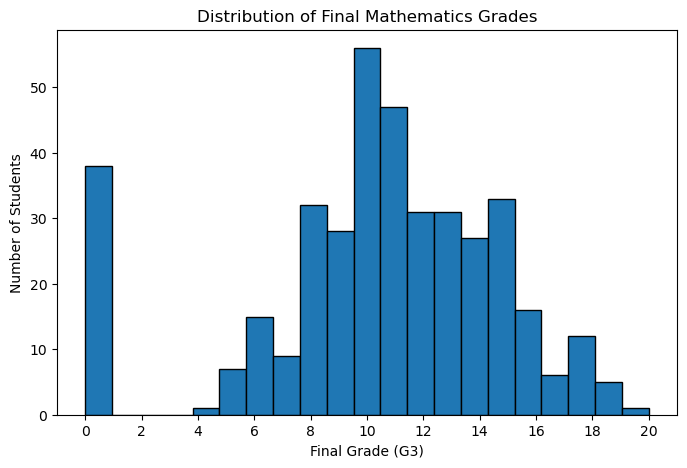

In [30]:
plt.figure(figsize=(8, 5))
plt.hist(df_original['G3'], bins=21, edgecolor='black')

plt.title('Distribution of Final Mathematics Grades')
plt.xlabel('Final Grade (G3)')
plt.ylabel('Number of Students')
plt.xticks(range(0, 21, 2))
plt.show()

The histogram shows that most final Mathematics grades (G3) are concentrated between 8 and 15. The most frequent grade is 10, while 38 students (approximately 9.6% of the dataset) received a final grade of zero. As grade 10 is the minimum passing grade, this distribution helps us understand how students are divided into Pass and Fail groups.

In [29]:
df_original.groupby('studytime')['G3'].mean()

studytime
1    10.047619
2    10.171717
3    11.400000
4    11.259259
Name: G3, dtype: float64

The results show that students who spend more time studying tend to have slightly higher average final grades. Students in study time category 3 (5 to 10 hours per week) had the highest average grade of 11.40. Students in study time category 4 (more than 10 hours per week) had a slightly lower average of 11.26 compared to category 3, suggesting that spending more time studying does not necessarily lead to higher grades. 

([<matplotlib.axis.XTick at 0x1524cf610>,
 [Text(0, 0, '<2h'),
  Text(1, 0, '2-5h'),
  Text(2, 0, '5-10h'),
  Text(3, 0, '>10h')])

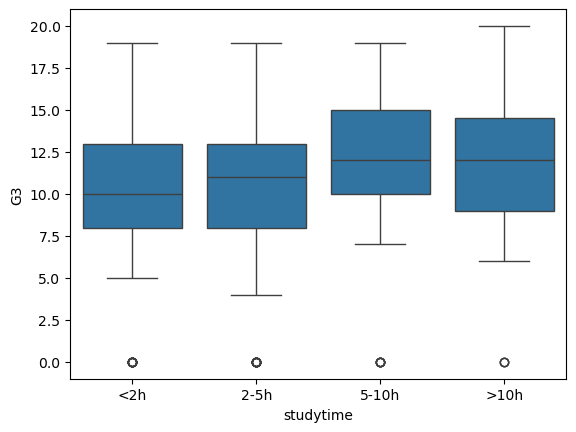

In [21]:
sns.boxplot(data=df_original, x='studytime', y='G3')
plt.xticks(
    ticks=[0, 1, 2, 3],
    labels=['<2h', '2-5h', '5-10h', '>10h']
)

The boxplot shows that the median grades are slightly higher for students who spend more time studying. However, the distributions overlap, showing that students from different study time categories can achieve similar grades.

In [32]:
df_original['studytime'].value_counts(normalize=True).sort_index().mul(100).round(2)

studytime
1    26.58
2    50.13
3    16.46
4     6.84
Name: proportion, dtype: float64

Most students (50.1%) belong to study time category 2, while only 6.8% belong to category 4. As category 4 has fewer students, its average grade should be interpreted with caution.

### 2.3 Previous Failures and Final Grade

This analysis examines the relationship between students' previous academic failures and their final Mathematics grades.


In [33]:
df_original['failures'].value_counts(normalize=True).sort_index().mul(100).round(2)

failures
0    78.99
1    12.66
2     4.30
3     4.05
Name: proportion, dtype: float64

The results show that most students (79%) had no previous class failures. Only a small percentage of students had two previous class failures (4.30%), while 4.05% had three previous class failures.

In [34]:
df_original.groupby('failures')['G3'].mean().round(2)

failures
0    11.25
1     8.12
2     6.24
3     5.69
Name: G3, dtype: float64

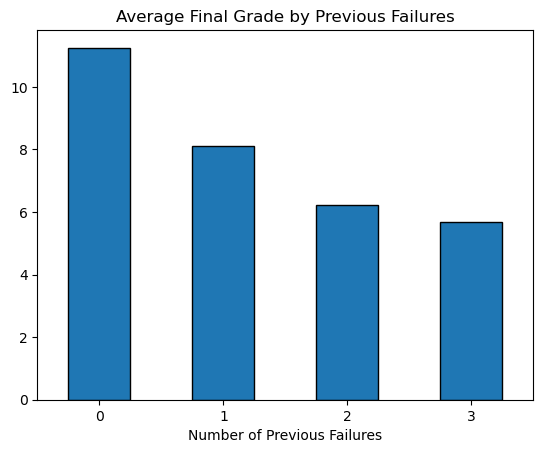

In [36]:
mean_grades = df_original.groupby('failures')['G3'].mean()

mean_grades.plot(kind='bar', edgecolor='black')

plt.title('Average Final Grade by Previous Failures')
plt.xlabel('Number of Previous Failures')
plt.xticks(rotation=0)
plt.show()

The average final grade decreases as the number of previous class failures increases, showing that students who had no previous class failures had the highest average grade in G3 (11.25), while those who had three previous class failures had a lower average grade (5.69). This suggests that previous class failures could be a useful feature for predicting whether a student will pass or fail Mathematics.

### 2.4 Absences and Final Grade

This analysis explores the relationship between the number of school absences and students' final Mathematics grades (G3).

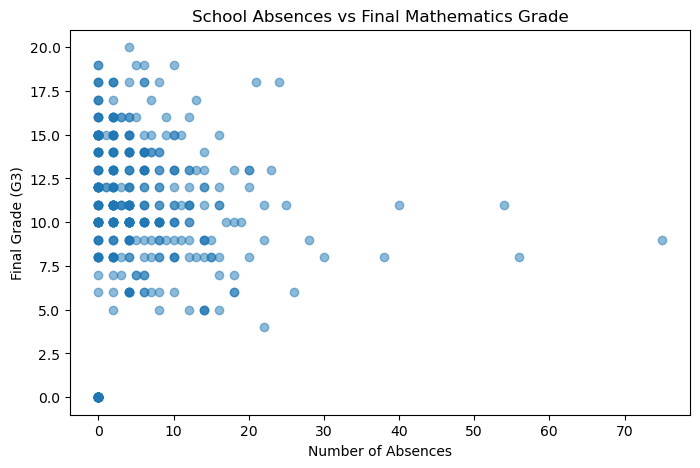

In [38]:
plt.figure(figsize=(8, 5))

plt.scatter(df_original['absences'], df_original['G3'], alpha=0.5)

plt.title('School Absences vs Final Mathematics Grade')
plt.xlabel('Number of Absences')
plt.ylabel('Final Grade (G3)')

plt.show()

The scatterplot shows that most students had between 0 and 20 absences. However, among students who had fewer absences, we can find practically the entire range of grades, from 0 to 20. There are also some students with a high number of absences, including one with more than 70 absences who still achieved a grade close to 9. This shows that we cannot identify a strong negative relationship based only on this plot.

In [39]:
df_original['absences'].corr(df_original['G3'])

np.float64(0.03424731615006931)